This lab explores the application of gradient descent to machine learning.

## Part I - Linear Regression


The goal of this problem is to show you how (higher dimensional) gradient descent can be used to find relationships between a feature (x) and response (y).

Suppose the **true** relationship is:

$$y = 2 + 3x + 4x^2 + error$$

We do **NOT** know this but have access to a data (a bunch of observations) from the above relationship. Let us say we have $n =30$ observations $(x_1, y_1), (x_2, y_2), \ldots (x_{30}, y_{30})$ from the above data set. Suppose we know that the relationship between $y$ and $x$ satisfies the functional relationship

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + error$$

However we do not know the values of the above constants and we want to learn this from the data. So we construct the error or loss function:

$$f(\beta_0, \beta_1, \beta_2) = \frac{1}{30}\sum_{i=1}^{30} (y_i - [\beta_0 + \beta_1 x_i + \beta_2 x_i^2] )^2$$

This is a measure of: "if $\beta_0, \beta_1, \beta_2$ are the correct values then our *prediction* of the $i$-th observation given the feature $x_i$ is $\hat{y}_i = \beta_0 + \beta_1 x_i + \beta_2 x_i^2$ so the above is a measure of **how bad the prediction of the true response** $y_i$ is **using the above values** of $\beta_0, \beta_1, \beta_2$.

## Goal

Find $\beta_0,\beta_1, \beta_2$ that **minimizes** the above function. Question: HOW??

One Answer: use gradient descent! Start with the initialization

$$\boldsymbol{\beta}(0) = \begin{bmatrix}
\beta_{0}(0) \\
\beta_{1}(0) \\
\beta_{2}(0)
\end{bmatrix} = \begin{bmatrix}
0 \\
0 \\
0
\end{bmatrix} $$

Then use the iterative scheme

$$\boldsymbol{\beta}(t+1) = \boldsymbol{\beta}(t) - \eta \nabla f(\boldsymbol{\beta}(t))$$

Here $\boldsymbol{\beta}(t)$ is the vector representing the estimates at iteration $t$:

$$\boldsymbol{\beta}(t) = \begin{bmatrix}
\beta_{0}(t) \\
\beta_{1}(t) \\
\beta_{2}(t)
\end{bmatrix} $$

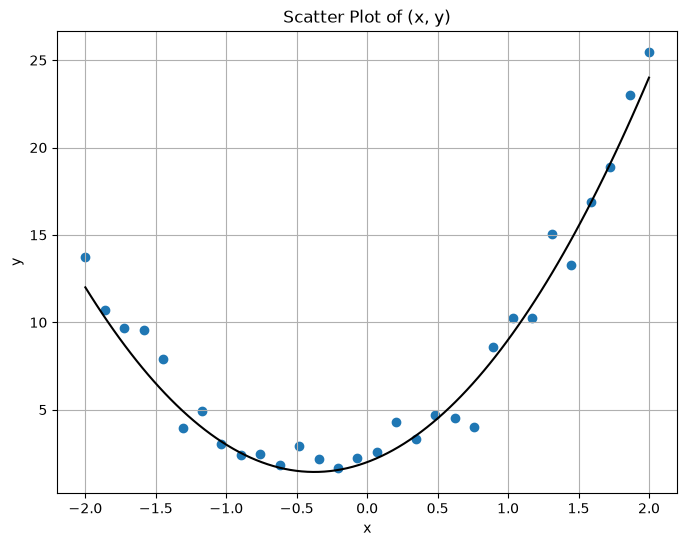

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---- The following code simulates some data based on the given relationship.

# Simulate data
np.random.seed(0)
x = np.linspace(-2, 2, 30)
error = np.random.normal(0, 1, 30)
y = 2 + 3*x + 4*x**2 + error

# Plot scatter plot of (x, y)
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label='Data Points')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter Plot of (x, y)')
plt.grid(True)

# True curve
true_curve_x = np.linspace(-2, 2, 100)
true_curve_y = 2 + 3*true_curve_x + 4*true_curve_x**2
plt.plot(true_curve_x, true_curve_y, 'k-', label='True Curve')


**Problem 1** Fill in the gradient to complete the `gradient_descent` function

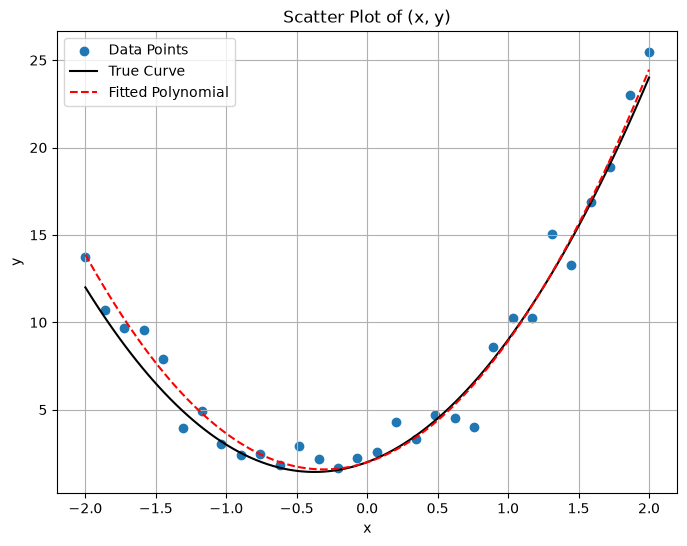

In [2]:
# ---- Now we pretend we don't know this relationship and use gradient descent to *learn* it
# the beta's above are the variables 'w' here for 'weights'
def gradient_descent(x, y, learning_rate, num_iterations):
    # Initialize parameters
    w0 = 0
    w1 = 0
    w2 = 0
    N = len(x)

    # Gradient descent
    for _ in range(num_iterations):
        y_pred = w0 + w1*x + w2*x**2
        error = y_pred - y
        # fill in the components of the gradient
        grad0 = (2/N) * np.sum(error)
        grad1 = (2/N) * np.sum(error * x**1)
        grad2 = (2/N) * np.sum(error * x**2)
        w0 -= learning_rate * grad0
        w1 -= learning_rate * grad1
        w2 -= learning_rate * grad2

    return w0, w1, w2

learning_rate = 0.001
num_iterations = 1000
w0, w1, w2 = gradient_descent(x, y, learning_rate, num_iterations)

# Plot scatter plot of (x, y)
plt.figure(figsize=(8, 6))
plt.scatter(x, y, label='Data Points')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter Plot of (x, y)')
plt.grid(True)

# True curve
true_curve_x = np.linspace(-2, 2, 100)
true_curve_y = 2 + 3*true_curve_x + 4*true_curve_x**2
plt.plot(true_curve_x, true_curve_y, 'k-', label='True Curve')

# Plot polynomial of degree 2 to fit the data
poly_fit_y = w0 + w1*true_curve_x + w2*true_curve_x**2
plt.plot(true_curve_x, poly_fit_y, 'r--', label='Fitted Polynomial')

plt.legend()
plt.show()

One downside is that we had to guess what terms to include in our prediction of the functional relationship.

Suppose the **true relationship** is:

$$y = 2 + 6x - 4x^2  + error$$

However for whatever reason we think that the relationship is of the form

$$y = \beta_0 + \beta_ 1 x + \beta_ 2 x^2 + \beta_3 x^3 +  error$$

leading us to try to solve the optimization goal (after observing the data): minimize the function:

$$f(\beta_0, \beta_1, \beta_2. \beta_3) = \frac{1}{30}\sum_{i=1}^{30} (y_i - [\beta_0 + \beta_1 x_i + \beta_2 x_i^2 + \beta_3 x_i^3 ] )^2$$


**Problem 2**  Modify your code from above to obtain this new relationship for the data.

Cubic coefficients: [ 2.02544453  6.05980856 -4.00605542  0.02357122]


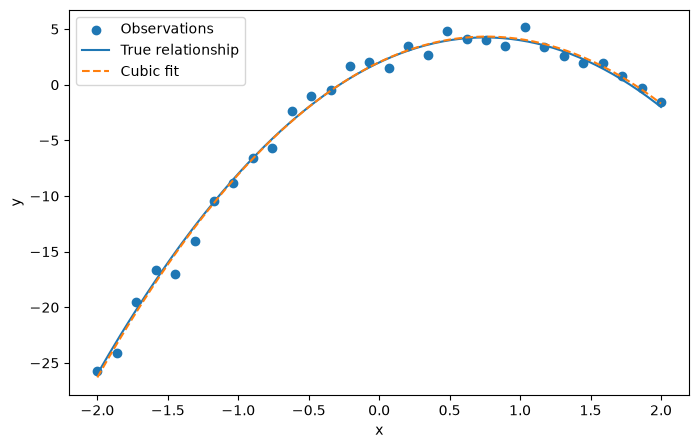

In [3]:
rng = np.random.default_rng(42)
x_cubic = np.linspace(-2, 2, 30)
y_cubic = 2 + 6*x_cubic - 4*x_cubic**2 + rng.normal(0, 1, 30)
def cubic_gradient_descent(x, y, learning_rate=0.001, num_iterations=20000):
    w = np.zeros(4)
    for _ in range(num_iterations):
        error = w[0] + w[1]*x + w[2]*x**2 + w[3]*x**3 - y
        gradient = (2/len(x))*np.array([np.sum(error), np.sum(error*x),
                                      np.sum(error*x**2), np.sum(error*x**3)])
        w -= learning_rate*gradient
    return w
w_cubic = cubic_gradient_descent(x_cubic, y_cubic)
print('Cubic coefficients:', w_cubic)
grid = np.linspace(-2, 2, 200)
plt.figure(figsize=(8, 5))
plt.scatter(x_cubic, y_cubic, label='Observations')
plt.plot(grid, 2+6*grid-4*grid**2, label='True relationship')
plt.plot(grid, sum(w_cubic[j]*grid**j for j in range(4)), '--', label='Cubic fit')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

# Part II - Logistic Regression Classifier

For one independent variable, a linear regression take the form $y = \beta_0 + \beta_1 x$.

We now consider a variation on linear regression tailored to classification problems. For simplicity, we will consider binary classification problems, with the two classes coded as 0 and 1. Our model will return a number `p` between 0 and 1, which you can think of as the "confidence" or "certainty" the model has that the given data point is a 1. You may have seen this described in other statistics classes as the "probability" that the given data point is 1. Our classifier will classify something as a 1 if `p>.5`, and as 0 otherwise.

You might consider trying to estimate `p` using linear regression. However, this will lead to values of `p` outside the interval [0,1], which is not what we want. Instead, we will use linear regression but take the y-value to be the so-called "log odds," or
$$ \log\left(\frac{p}{1-p}\right).$$
 This function maps the interval [0,1] to the entire real line, so it is a more suitable target for linear regression. The, once we've fit the model, we can solve for the estimated value of `p` given any data point (by reversing the log-odds transformatinon). This model results in a characteristic "logistic curve" for the predicted probabilies, which we will see in a plot below.

Let's first plot the log-odds function, so you can see that the claim about mapping [0,1] to the real line is true.

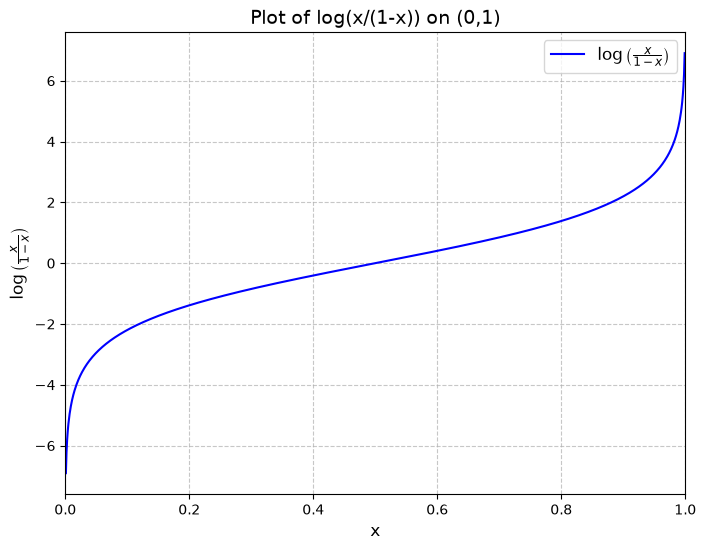

In [4]:
def log_odds(x):
    return np.log(x / (1 - x))

# Generate x values in the interval (0,1)
x = np.linspace(0.001, 0.999, 1000)  # Avoid 0 and 1 to prevent division by zero and log(0)

# Compute y values
y = log_odds(x)

# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(x, y, label=r'$\log\left(\frac{x}{1-x}\right)$', color='blue')

# Add labels and title
plt.xlabel('x', fontsize=12)
plt.ylabel(r'$\log\left(\frac{x}{1-x}\right)$', fontsize=12)
plt.title('Plot of log(x/(1-x)) on (0,1)', fontsize=14)

# Add grid and legend
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)

# Set x-axis limits
plt.xlim(0, 1)

# Show the plot
plt.show()

In [5]:
from sklearn.datasets import load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

ModuleNotFoundError: No module named 'sklearn'

We will build a classifier to tell which region the wine comes from based on one or more of its features.

In [ ]:
data = load_wine()
X = data.data[:, 0].reshape(-1, 1)  # Use only the first feature (alcohol content) and reshape the vector
y = data.target                     # Original classes (0, 1, 2)

In [ ]:
# here are the possible features
data.feature_names

In [ ]:
# There are three wine regions, but we will only work with two
mask = (y == 0) | (y == 1)
X = X[mask]
y = y[mask]

In [ ]:
#split into test and train sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Train logistic regression
model = LogisticRegression()
model.fit(X_train, y_train)

# Print accuracy and coefficients
print(f"Test Accuracy: {model.score(X_test, y_test):.2f}")
print(f"Coefficient (slope): {model.coef_[0][0]:.2f}")
print(f"Intercept: {model.intercept_[0]:.2f}")

In [ ]:
# Here is some visualization of the data and decision boundary

X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
probabilities = model.predict_proba(X_range)[:, 1]  # P(class=1)

# Plot the data and decision boundary
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, c=y_train, cmap='viridis', edgecolors='k', label='Data (Class 0 vs Class 1)')
plt.plot(X_range, probabilities, color='red', linewidth=2, label='P(Class 1)')
plt.axhline(0.5, color='black', linestyle='--', label='Decision Boundary (p=0.5)')

plt.xlabel('Alcohol Content')
plt.ylabel('Probability (Class 1)')
plt.title('Single-Variable Logistic Regression: Class 0 vs Class 1 (Wine Dataset)')
plt.yticks([0, 1], ['Class 0', 'Class 1'])  # Label y-axis with class names
plt.legend()
plt.grid(True)
plt.show()

For your own understanding, in the above plot which data points get miss classified?

**Problem 3** Pick a different feature (independent variable) from the wine dataset. (You may wish to look back at the previous lab that used this dataset to see the list of features.) Using this dataset, and dropping the third region (as above), run a single-variable logistic regression using your chosen independent variable to build a predictor that predicts which of the first two regions the wine came from. Print the accuracy on a 20/80 test-train split, and provide a plot of the predicted probabilities as a function of the independent variable.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
wine = load_wine()
wine_mask = wine.target < 2
wine_X, wine_y = wine.data[wine_mask], wine.target[wine_mask]
train_idx, test_idx = train_test_split(np.arange(len(wine_y)), test_size=0.2,
                                     random_state=42, stratify=wine_y)
feature_idx = wine.feature_names.index('flavanoids')
def fit_wine(indices):
    classifier = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    classifier.fit(wine_X[train_idx][:, indices], wine_y[train_idx])
    return classifier
single_model = fit_wine([feature_idx])
single_accuracy = single_model.score(wine_X[test_idx][:, [feature_idx]], wine_y[test_idx])
print(f'Flavanoids test accuracy: {single_accuracy:.4f}')
feature_grid = np.linspace(wine_X[:, feature_idx].min(), wine_X[:, feature_idx].max(), 200)
plt.figure(figsize=(8, 5))
plt.scatter(wine_X[train_idx, feature_idx], wine_y[train_idx], label='Training data')
plt.plot(feature_grid, single_model.predict_proba(feature_grid[:, None])[:, 1], 'r', label='P(class 1)')
plt.axhline(.5, linestyle='--', color='gray')
plt.xlabel('Flavanoids'); plt.ylabel('P(class 1)'); plt.legend(); plt.show()

**Problem 4** Try out some more features of the data set.  In addition to Alcohol content, what is another feature that is good at classifying the data?  What is one feature that is bad at classifying the data?

In [ ]:
feature_scores = []
for j, name in enumerate(wine.feature_names):
    classifier = fit_wine([j])
    score = classifier.score(wine_X[test_idx][:, [j]], wine_y[test_idx])
    feature_scores.append(score)
    print(f'{name:30s} {score:.4f}')
# Identify the best non-alcohol feature and the weakest feature on this split.
good_idx = max(range(1, len(feature_scores)), key=lambda j: feature_scores[j])
bad_idx = int(np.argmin(feature_scores))
print(f'Good feature: {wine.feature_names[good_idx]} ({feature_scores[good_idx]:.4f})')
print(f'Bad feature: {wine.feature_names[bad_idx]} ({feature_scores[bad_idx]:.4f})')

Proline is a good feature on this split (96.15% accuracy); malic acid is a poor feature (50.00%).

Can we do better with two features instead of one?

In [ ]:
# Select two features (e.g., alcohol + malic acid)
X2 = data.data[:, :2][mask]  # Features 0 (alcohol) and 1 (malic acid)
y2 = y  # Same binary target (Class 0 vs Class 1)

# Split into train/test (new variable names)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2)

# Train logistic regression
model2 = LogisticRegression()
model2.fit(X2_train, y2_train)

print(f"Test Accuracy (2 variables): {model2.score(X2_test, y2_test):.2f}")
print(f"Coefficients: {model2.coef_[0]}")
print(f"Intercept: {model2.intercept_[0]}")

In [ ]:
# Create a grid to plot decision boundary
x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

# Predict probabilities for the grid
Z = model2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape)

# Plot decision boundary and data
plt.figure(figsize=(10, 6))

# Make the colormap
contour = plt.contourf(xx, yy, Z, levels=np.linspace(0, 1, 11), cmap='viridis', alpha=0.6)
plt.colorbar(contour, label='P(Class 1)')

# Highlight the decision boundary (P=0.5)
decision_boundary = plt.contour(xx, yy, Z, levels=[0.5], colors='white', linewidths=2, linestyles='dashed')
plt.clabel(decision_boundary, inline=True, fmt='P=0.5', fontsize=10)

# Scatter plot of data points
scatter = plt.scatter(X2_train[:, 0], X2_train[:, 1], c=y2_train, cmap='viridis', edgecolors='k', label='Data')
plt.xlabel('Alcohol Content')
plt.ylabel('Malic Acid')
plt.title('Two-Variable Logistic Regression: Decision Boundary (Class 0 vs Class 1)')

# Manually add legend for class labels
legend_labels = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='yellow', markersize=8, label='Class 0'),
                 plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='purple', markersize=8, label='Class 1')]
plt.legend(handles=legend_labels)

plt.show()

For your own understanding, in the above plot which data points get miss classified?

**Problem 5** Pick a different set of two features from the wine dataset and retrain your classifier.  Print the accuracy on a 20/80 test-train split, and provide a plot of the decision boundary.  How do the results compare to your 'good' and 'bad' cases above?

In [ ]:
pair_indices = [good_idx, bad_idx]
pair_model = fit_wine(pair_indices)
pair_accuracy = pair_model.score(wine_X[test_idx][:, pair_indices], wine_y[test_idx])
print(f'Two-feature test accuracy: {pair_accuracy:.4f}')
print(f'Good alone: {feature_scores[good_idx]:.4f}; bad alone: {feature_scores[bad_idx]:.4f}')
a, b = wine_X[:, good_idx], wine_X[:, bad_idx]
xx, yy = np.meshgrid(np.linspace(a.min()-.1, a.max()+.1, 200),
                     np.linspace(b.min()-.1, b.max()+.1, 200))
zz = pair_model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), cmap='viridis', alpha=.6)
plt.colorbar(label='P(class 1)')
plt.contour(xx, yy, zz, levels=[.5], colors='black', linestyles='--')
for cls in [0, 1]:
    rows = train_idx[wine_y[train_idx] == cls]
    plt.scatter(a[rows], b[rows], label=f'Class {cls}')
plt.xlabel(wine.feature_names[good_idx]); plt.ylabel(wine.feature_names[bad_idx])
plt.legend(); plt.show()

Using proline and malic acid together gives 96.15% accuracy. This matches proline alone and is better than malic acid alone; the second feature did not improve test accuracy in this experiment.

# Part III - logistic regession image classifier

Now we consider an example of logistic regression with many features. We will consider the binary classification problem of telling handwritten `1`'s from `7`'s, using the MNIST dataset from a previous lab. (You may wish to revisit the classification lab to reminder yourself how this dataset is structured.) The features are the numerical values of each pixel (representing how dark it is). We'll write out the exact equations in class.


In [ ]:
# load data -- note I was having issues with fetch_openml that we used before so I changed to this method
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_mnist = X_train.reshape(-1, 28*28)  # flatten the 28x28 images into vectors of size 782
y_mnist = y_train

# Filter for only digits 1 and 7
mask = (y_mnist == 1) | (y_mnist == 7)  # in this data set, the target is not a string
X_binary = X_mnist[mask]
y_binary = y_mnist[mask]

# Convert labels to binary (0 for '1', 1 for '7')
y_binary = (y_binary == 7).astype(int)

In [ ]:
# Split into train/test sets (80/20 split)
X_train_mnist, X_test_mnist, y_train_mnist, y_test_mnist = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42
)

# Train logistic regression (linear model for classification)
mnist_model = LogisticRegression(max_iter=1000)
mnist_model.fit(X_train_mnist, y_train_mnist)

# Evaluate on test set
y_pred = mnist_model.predict(X_test_mnist)
accuracy = accuracy_score(y_test_mnist, y_pred)
conf_matrix = confusion_matrix(y_test_mnist, y_pred)

print(f"Test Accuracy (1 vs. 7): {accuracy:.4f}")

In [ ]:
# Create a labeled display
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,
                             display_labels=['1', '7'])  # Match your binary encoding (0=1, 1=7)

# Plot with labels
fig, ax = plt.subplots(figsize=(6,6))
disp.plot(cmap='Blues', ax=ax, values_format='d')  # 'd' for integer formatting
plt.title("Confusion Matrix (1 vs 7 Classification)")
plt.grid(False)  # Remove grid lines for cleaner look
plt.show()

In [ ]:
# Plot some misclassified examples
misclassified = np.where(y_pred != y_test_mnist)[0]
plt.figure(figsize=(10, 4))
for i, idx in enumerate(misclassified[:5]):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test_mnist[idx].reshape(28, 28), cmap='gray')
    plt.title(f"True: {y_test_mnist[idx]}\nPred: {y_pred[idx]}")
    plt.axis('off')
plt.suptitle("Misclassified Examples (1 vs. 7)", y=1.05)
plt.tight_layout()
plt.show()

**Problem 6** Use logistic regression on the MNIST dataset to build a classifier that distinguishes `3`'s from `8`'s. Evaluate it on a 20/80 test-train split. Print the test set accuracy and a confusion matrix.

Again, you can do this rather straightfowardly by adapting the previous code. Provide your code below.

In [ ]:
digit_mask = np.isin(y_mnist, [3, 8])
X_38 = X_mnist[digit_mask].astype('float32') / 255.0
y_38 = (y_mnist[digit_mask] == 8).astype(int)
X38_train, X38_test, y38_train, y38_test = train_test_split(
    X_38, y_38, test_size=.2, random_state=42, stratify=y_38)
model_38 = LogisticRegression(max_iter=2000)
model_38.fit(X38_train, y38_train)
pred_38 = model_38.predict(X38_test)
print(f'Test accuracy (3 vs 8): {accuracy_score(y38_test, pred_38):.4f}')
cm_38 = confusion_matrix(y38_test, pred_38)
print('Confusion matrix (rows=true, columns=predicted; order 3, 8):\n', cm_38)
ConfusionMatrixDisplay(cm_38, display_labels=['3', '8']).plot(cmap='Blues', values_format='d')
plt.title('Logistic regression: 3 vs 8'); plt.grid(False); plt.show()

# Part IV - Neural Net classifier

We will continue to work with the MNIST digits, using a softmax regression model for classifying the handwritten digits.  This is a neural network with no hidden layer.

The other change is we are telling the machine what algorithm to use to search for global minimum.  In this case, the optimizer is `sgd` (stochastic gradient descent), and the loss function is the cross-entropy. The `batch_size` parameter controls how the number of randomly subsampled points used to estimate the gradient at each step.

From Wikipedia: The term "softmax" derives from the amplifying effects of the exponential on any maxima in the input tuple. For example, the standard softmax of
$\displaystyle (1,2,8)$ is approximately
$\displaystyle (0.001,0.002,0.997)$, which amounts to assigning almost all of the total unit weight in the result to the position of the tuple's maximal element (of 8).

First we rescale the values of the pixels. Orignally on a scale from 0 to 255, we put them in the range [0,1]. This is not necessary, strictly speaking, but it is common to standardize data in this way (so parameters like the learning rate can easily be compared on a common scale between different models).

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

In [ ]:
# reload data -- just to start clean here
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_mnist = X_train.reshape((-1, 28 * 28))
X_test = X_test.reshape(-1, 28 * 28)  # flatten the 28x28 images into vectors of size 782

# Normalize the input images to [0, 1] range
X_mnist = X_mnist.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# We also conver the labels to vectors using one-hot encoding
y_mnist_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [ ]:
# Basic visualization of some MNIST elements
def visualize_mnist(x_data, y_data, num_samples):
    plt.figure(figsize=(10, 2))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(x_data[i], cmap='gray')
        plt.title(f"Label: {y_data[i]}")
        plt.axis('off')
    plt.show()

# Visualize some training samples
visualize_mnist(X_train, y_train, num_samples=5)

In [ ]:
# Label vectors match the images above
print(y_train[0],y_train[1],y_train[2],y_train[3],y_train[4])
print(y_mnist_cat[0],y_mnist_cat[1],y_mnist_cat[2],y_mnist_cat[3],y_mnist_cat[4])

In [ ]:
# set up the model, defining the layers
softmax_model = models.Sequential([
    layers.Input(shape=(784,)), # input layer, 784 is number of features
    layers.Dense(10, activation='softmax') # output layer, 10 since dim of output
])

# set other options, these typically have default settings if we don't perscribe
softmax_model.compile(optimizer='sgd',
                      loss='categorical_crossentropy',
                      metrics=['accuracy'])

print("Training Softmax Regression Model...")
softmax_model.fit(X_mnist, y_mnist_cat, epochs=10, batch_size=32)

# Evaluate on test data
test_loss, test_acc = softmax_model.evaluate(X_test, y_test_cat)
print(f"Softmax Regression Test Accuracy: {test_acc:.4f}")

**Problem 7** Here we have added a hidden layer to the network with the `relu` activation function.  Run it and note the accuracy.  Replace the `relu` with the `tanh` activation function and comment on the accuracy.

ReLU is "rectified linear unit" given by
$$
f(x) = \frac{|x| + x}{2}
$$  It is zero until 0 and then increases like $x$ for positive values.  Tanh is the hyperbolic tangent give by
$$
f(x) = \frac{e^{x}-e^{-x}}{e^x+e^{-x}}
$$
It goes to $-1$ as $x\to - \infty$ and $1$ as $x \to \infty$.

In [ ]:
# Multilayer Perceptron (MLP) with One Hidden Layer
mlp_model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'), # this is the hidden layer
    layers.Dense(10, activation='softmax')
])

mlp_model.compile(optimizer='sgd',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

print("\nTraining MLP Model...")
mlp_model.fit(X_mnist, y_mnist_cat, epochs=10, batch_size=32)

# Evaluate on test data
test_loss, test_acc = mlp_model.evaluate(X_test, y_test_cat)
print(f"MLP Test Accuracy: {test_acc:.4f}")

In [ ]:
relu_accuracy = test_acc
# Multilayer Perceptron (MLP) with One Hidden Layer
tanh_model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='tanh'), # this is the hidden layer
    layers.Dense(10, activation='softmax')
])

tanh_model.compile(optimizer='sgd',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

print("\nTraining MLP Model...")
tanh_model.fit(X_mnist, y_mnist_cat, epochs=10, batch_size=32)

# Evaluate on test data
test_loss, tanh_accuracy = tanh_model.evaluate(X_test, y_test_cat)
print(f"MLP Test Accuracy: {tanh_accuracy:.4f}")
print(f"ReLU accuracy: {relu_accuracy:.4f}; tanh accuracy: {tanh_accuracy:.4f}")


ReLU achieved 95.18% accuracy, while tanh achieved 94.38%. ReLU performed slightly better in this run, by 0.80 percentage points.

We now load the Fashion MNIST dataset

In [ ]:
# Load the Fashion MNIST dataset
from tensorflow.keras.datasets import fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Visualize some training data
visualize_mnist(x_train, y_train, num_samples=5)

# Normalize the pixel values to be between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten the 28x28 images into vectors of size 784
x_train_f = x_train.reshape(-1, 28 * 28)
x_test_f = x_test.reshape(-1, 28 * 28)

# One-hot encode the labels
y_train_f = to_categorical(y_train, 10)
y_test_f = to_categorical(y_test, 10)

**Problem 8** What do the labels 0, 3, and 9 indicate?

Labels **0, 3, and 9** represent **T-shirt/top, Dress, and Ankle boot**, respectively. Source: [Keras dataset documentation](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data).

**Problem 9** Train a neural network that achieves 87.5% accuracy on the test set `y_test_f`

**Hint.** Just copying the architecture from the previous part won't be quite good enough. Try making the hidden layer larger, adding another hidden layer (or more than one, perhaps with decreasing sizes), training for more epochs, and adjusting the learning rate of SGD. Code that you can use to change the learning rate is below. The default (use in the examples above) is 0.01. If you get really stuck, you can try copying the convolutional network shown in the slides, instead of just using a multi-layer perceptron.

In [ ]:
'''
from tensorflow.keras.optimizers import SGD
my_sgd = SGD(learning_rate=0.01)

mlp_model.compile(optimizer=my_sgd,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
'''

In [ ]:
import tensorflow as tf
from tensorflow.keras.optimizers import SGD
tf.keras.utils.set_random_seed(42)
fashion_model = models.Sequential([layers.Input(shape=(784,)),
    layers.Dense(512, activation='relu'), layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax')])
fashion_model.compile(optimizer=SGD(learning_rate=.05, momentum=.9),
                      loss='categorical_crossentropy', metrics=['accuracy'])
fashion_history = fashion_model.fit(x_train_f, y_train_f, validation_split=.1,
    epochs=40, batch_size=128, verbose=2,
    callbacks=[tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=3),
               tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)])
fashion_loss, fashion_accuracy = fashion_model.evaluate(x_test_f, y_test_f, verbose=0)
print(f'Fashion MNIST test accuracy: {fashion_accuracy:.4f} ({100*fashion_accuracy:.2f}%)')
assert fashion_accuracy >= .875, 'Required test accuracy not reached'
plt.figure(figsize=(8, 5))
plt.plot(fashion_history.history['accuracy'], label='Training')
plt.plot(fashion_history.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

The model achieved 89.71% test accuracy, exceeding the required 87.5%.